<a href="https://colab.research.google.com/github/J3remy1/east-river-water-quality/blob/main/notebooks/03_estuary_2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

sheet_id = "1OWoGztuQ9yhjH6Zk2wkHTvdFntbIvfU11MXhp4X20og"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=xlsx"
tabs = pd.read_excel(url, sheet_name=["Chemistry", "Standardized Salinity"])

chem = tabs["Chemistry"]
sal = tabs["Standardized Salinity"]
chem.columns = chem.columns.str.strip()
sal.columns = sal.columns.str.strip()

print(chem.shape, sal.shape)

(91, 16) (997, 11)


In [2]:
print(chem["DO: Reading (units) ppm/ mg/L"].unique())
print(chem["Percent Saturation of Dissolved Oxygen"].unique())

['10 ppm' 7 '8 mg/L' 10 '8 ppm' 15 6 '12 ppm' '9 ppm' '6ppm' '9ppm'
 '10.23 ppm' nan '11 ppm' '14ppm' 0 '10 PPM' 14 '4 ppm' 11 ' 8ppm' 8
 '8ppm' '9.01 mg/L' 8.099 '9 mg/L' '13 ppm' '5.0 ppm' '9.95 mg/L' 9.32
 '8.0 ppm' 6.5 '7 ppm' '6 ppm' '7.43 mg/L' 7.7 9 '2 ppm' '7ppm' '8 PPM'
 '3ppm' '5.7-6' '6.5 ppm']
[0.88 65 0.93 0.75 0.98 0.65 135 55 105 0.95 0.45 nan 0.9 1 100 115 0.89
 70 'unable to be measured' 1.05 90 140 116 0.85 0.48 0.84 0.67 85 0.92
 1.3 0.86 0.81 0.83 1.09 80 1.158 106.6 0.68 120 88.4 82.5 0.7 60 97
 '78%%' 0.12 '60-64%' 62.5]


In [3]:
import re
import numpy as np

def to_number(value):
    """Pull the number out of entries like '10 ppm', '8 mg/L', or '5.7-6'."""
    if pd.isna(value):
        return np.nan
    nums = re.findall(r"\d+\.?\d*", str(value))
    if len(nums) == 1:
        return float(nums[0])
    if len(nums) == 2:
        return (float(nums[0]) + float(nums[1])) / 2
    return np.nan

def to_percent(value):
    """Saturation as a percent; values typed as 88% are stored as 0.88."""
    x = to_number(value)
    if x <= 2:
        return x * 100
    return x

chem["do_ppm"] = chem["DO: Reading (units) ppm/ mg/L"].apply(to_number)
chem["sat_reported"] = chem["Percent Saturation of Dissolved Oxygen"].apply(to_percent)

print(chem["do_ppm"].notna().sum(), chem["sat_reported"].notna().sum())

79 62


In [4]:
raw = chem["Percent Saturation of Dissolved Oxygen"]
print(raw[raw.notna() & chem["sat_reported"].isna()])

22    unable to be measured
Name: Percent Saturation of Dissolved Oxygen, dtype: object


In [5]:
def first_number(value):
    """River mile from entries like '25.4', '-4.5', 'ER 15.2', or 'HrlmRM13'."""
    if pd.isna(value):
        return np.nan
    nums = re.findall(r"-?\d+\.?\d*", str(value))
    if nums:
        return float(nums[0])
    return np.nan

chem["river"] = chem["River"].str.strip()
chem["rm"] = chem["RM"].apply(first_number)
chem["temp_c"] = pd.to_numeric(chem["Water Temperature: Reading (Celsius)"], errors="coerce")

sal["river"] = sal["River"].str.strip()
sal["rm"] = sal["River Mile (RM)"].apply(first_number)
sal["salinity_ppt"] = pd.to_numeric(sal["Total Salinity ppm"], errors="coerce") / 1000

sal_by_rm = sal.groupby(["river", "rm"])["salinity_ppt"].median().reset_index()
df = chem.merge(sal_by_rm, on=["river", "rm"], how="left")

print(df.shape, df["rm"].isna().sum(), df["salinity_ppt"].notna().sum())

(91, 22) 4 63


In [6]:
def do_saturation(temp_c, salinity_ppt):
    """Dissolved oxygen at saturation, mg/L, 1 atm (Weiss 1970)."""
    T = temp_c + 273.15
    A1, A2, A3, A4 = -173.4292, 249.6339, 143.3483, -21.8492
    B1, B2, B3 = -0.033096, 0.014259, -0.0017000
    ln_c = (A1 + A2 * (100 / T) + A3 * np.log(T / 100) + A4 * (T / 100)
            + salinity_ppt * (B1 + B2 * (T / 100) + B3 * (T / 100) ** 2))
    return np.exp(ln_c) * 1.42903

df["sat_fresh"] = 100 * df["do_ppm"] / do_saturation(df["temp_c"], 0)
df["sat_salty"] = 100 * df["do_ppm"] / do_saturation(df["temp_c"], df["salinity_ppt"])

has_all = df["sat_reported"].notna() & df["sat_fresh"].notna()
salty = df[(df["salinity_ppt"] > 10) & has_all]
fresh = df[(df["salinity_ppt"] < 1) & has_all]

for name, part in [("salty sites", salty), ("fresh sites", fresh)]:
    gap_fresh = part["sat_reported"] - part["sat_fresh"]
    gap_salty = part["sat_reported"] - part["sat_salty"]
    print(name, len(part),
          "| median gap vs fresh:", round(gap_fresh.median(), 1),
          "| vs salinity-corrected:", round(gap_salty.median(), 1),
          "| within 5 pts of fresh:", (gap_fresh.abs() <= 5).sum())

salty sites 22 | median gap vs fresh: -0.3 | vs salinity-corrected: -11.4 | within 5 pts of fresh: 17
fresh sites 13 | median gap vs fresh: -0.5 | vs salinity-corrected: -0.5 | within 5 pts of fresh: 11


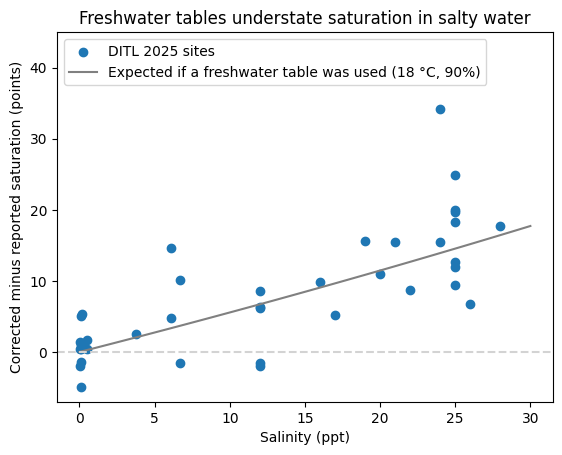

In [7]:
import matplotlib.pyplot as plt

plot = df[has_all & df["salinity_ppt"].notna()]
gap = plot["sat_salty"] - plot["sat_reported"]

s_line = np.linspace(0, 30, 100)
theory = 90 * (do_saturation(18, 0) / do_saturation(18, s_line) - 1)

plt.scatter(plot["salinity_ppt"], gap, label="DITL 2025 sites")
plt.plot(s_line, theory, color="gray", label="Expected if a freshwater table was used (18 °C, 90%)")
plt.axhline(0, linestyle="--", color="lightgray")

plt.xlabel("Salinity (ppt)")
plt.ylabel("Corrected minus reported saturation (points)")
plt.title("Freshwater tables understate saturation in salty water")
plt.legend(loc="upper left")
plt.ylim(-7, 45)
plt.show()

## Findings: estuary-wide, 2025

**Question.** Did the freshwater-table problem found in my class's data (notebook 02) happen across the whole Day in the Life program?

**Data.** Lamont-Doherty's compiled 2025 Day in the Life data (Chemistry and Standardized Salinity tabs): about 90 sites from the Adirondacks to New York Harbor, including the East and Harlem Rivers. Salinity was matched to each site by river and river mile; where several salinity readings shared a river mile, the median was used.

**Control.** At 13 freshwater sites (salinity below 1 ppt), reported saturation matched the freshwater calculation (median difference −0.5 points), as it should. Where a freshwater table is correct, my parsing and the Weiss (1970) calculation agree with the sites' own numbers.

**Result.** At 22 salty sites (above 10 ppt), reported saturation also matched the freshwater calculation (median difference −0.3 points; 17 of 22 within 5 points), but fell a median 11.4 points below the salinity-corrected value. The gap grows with salinity and roughly follows the curve expected if a freshwater table were used. At 24–26 ppt, it ranged from about 7 to 34 points (median about 17). What my class's data showed was not one school's mistake: in 2025, schools across the program appear to have used freshwater saturation tables in brackish and salt water.

**An exception that supports the result.** Both readings from the Center for the Urban River at Beczak were taken with a meter, and their reported saturation (115.8% and 106.6%) matches the salinity-corrected values (113.8% and 105.1%), not the freshwater ones (105.9% and 97.8%). The meter may have been set to correct for salinity; the data do not say. Another meter site, Randall's Island, matched the freshwater value instead.

**Cleaning rules.** Numbers were extracted from text entries such as "10 ppm" or "8 mg/L"; the two ranges ("5.7-6" for DO and "60-64%" for saturation) were replaced by their midpoints. Saturation entered as a fraction (0.88) was converted to a percent. Salinity marked BD (below detection) was treated as missing. Four upstream and tributary sites with no numeric river mile were left out; all are fresh water.

**Limitations.** One year only. Salinity was matched by river mile rather than measured alongside each DO reading. Most DO readings come from test kits that read whole numbers, so each saturation value is uncertain by roughly ±10 to 13 points. The data were collected by students using different equipment, and Lamont notes that accuracy varies by site.

*Data: Lamont-Doherty Earth Observatory, A Day in the Life of the Hudson & Harbor, 2025 cumulative data. Method: Weiss, R. F. (1970), Deep-Sea Research, 17, 721–735.*

